# Biological Classification Challenge

## Probability-Based Independence Analysis Using the UCI Mushroom Dataset

### Objective

This project uses the UCI Mushroom Dataset to investigate the relationship between mushroom characteristics using probability.

We define the following events:

- **A**: Mushroom has a foul odor
- **B**: Mushroom has a brown cap color
- **C**: Mushroom is poisonous

The analysis is divided into two phases:

### Phase 1 — Independence Check

We test whether events A and B are independent using:

\[
P(A \cap B) = P(A) \times P(B)
\]

If the two values are not equal, A and B are dependent.

### Phase 2 — Conditional Independence Check

We restrict the dataset to poisonous mushrooms (C) and test:

\[
P(A \cap B \mid C) = P(A \mid C) \times P(B \mid C)
\]

This determines whether A and B are conditionally independent given that the mushroom is poisonous.

## 1. Dataset Loading and Preparation

The dataset used is the **UCI Mushroom Dataset** (`agaricus-lepiota.data`).

The dataset contains:

- **8124 mushroom records**
- **22 descriptive features**
- **1 class attribute**
- Class labels:
  - `e` → Edible
  - `p` → Poisonous

The original `.data` file does not contain column headers. Therefore, the column names are assigned manually while loading the dataset.

Only the features required for this probability analysis will be used:

- `class`
- `cap-color`
- `odor`

In [1]:
import pandas as pd

columns = [
    "class", "cap-shape", "cap-surface", "cap-color", "bruises",
    "odor", "gill-attachment", "gill-spacing", "gill-size",
    "gill-color", "stalk-shape", "stalk-root",
    "stalk-surface-above-ring", "stalk-surface-below-ring",
    "stalk-color-above-ring", "stalk-color-below-ring",
    "veil-type", "veil-color", "ring-number", "ring-type",
    "spore-print-color", "population", "habitat"
]

df = pd.read_csv(
    "agaricus-lepiota.data",
    header=None,
    names=columns
)

print(df.shape)
print(df.head())

(8124, 23)
  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w 

In [2]:
A = df["odor"] == "f"          # foul odor
B = df["cap-color"] == "n"     # brown cap
C = df["class"] == "p"         # poisonous

In [3]:
N = len(df)

count_A = A.sum()
count_B = B.sum()
count_AB = (A & B).sum()

P_A = count_A / N
P_B = count_B / N
P_AB = count_AB / N

print("Total:", N)
print("Foul odor:", count_A)
print("Brown cap:", count_B)
print("Foul + Brown:", count_AB)

print("P(A) =", P_A)
print("P(B) =", P_B)
print("P(A ∩ B) =", P_AB)
print("P(A) × P(B) =", P_A * P_B)

Total: 8124
Foul odor: 2160
Brown cap: 2284
Foul + Brown: 288
P(A) = 0.2658788774002954
P(B) = 0.2811422944362383
P(A ∩ B) = 0.03545051698670606
P(A) × P(B) = 0.07474979763445036


In [4]:
poisonous = df[df["class"] == "p"]

print("Poisonous mushrooms:", len(poisonous))

Poisonous mushrooms: 3916


In [5]:
P_A_given_C = (poisonous["odor"] == "f").mean()

P_B_given_C = (poisonous["cap-color"] == "n").mean()

P_AB_given_C = (
    (poisonous["odor"] == "f") &
    (poisonous["cap-color"] == "n")
).mean()

print("P(A|C) =", P_A_given_C)
print("P(B|C) =", P_B_given_C)
print("P(A ∩ B|C) =", P_AB_given_C)
print("P(A|C) × P(B|C) =", P_A_given_C * P_B_given_C)

P(A|C) = 0.5515832482124617
P(B|C) = 0.2604698672114402
P(A ∩ B|C) = 0.0735444330949949
P(A|C) × P(B|C) = 0.1436708154179548


In [7]:
print("\n--- CONCLUSION ---")

if abs(P_AB - P_A * P_B) < 1e-10:
    print("A and B are INDEPENDENT")
else:
    print("A and B are DEPENDENT")

if abs(P_AB_given_C - P_A_given_C * P_B_given_C) < 1e-10:
    print("A and B are CONDITIONALLY INDEPENDENT given C")
else:
    print("A and B are NOT CONDITIONALLY INDEPENDENT given C")


--- CONCLUSION ---
A and B are DEPENDENT
A and B are NOT CONDITIONALLY INDEPENDENT given C


## 6. Key Takeaways

- **A** represents foul odor.
- **B** represents brown cap color.
- **C** represents poisonous mushrooms.
- Independence is tested using:

\[
P(A \cap B) = P(A)P(B)
\]

- Conditional independence is tested using:

\[
P(A \cap B \mid C)
=
P(A \mid C)P(B \mid C)
\]

- A difference between the two sides indicates dependence.
- Filtering the dataset to poisonous mushrooms allows us to calculate probabilities conditioned on event C.
- The analysis demonstrates how probability can be used to investigate relationships between categorical features.

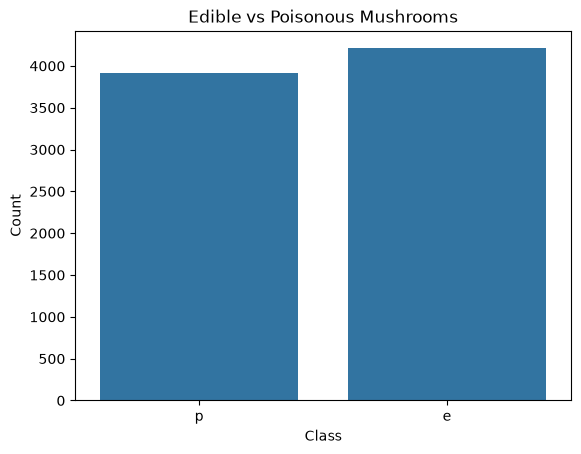

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="class")
plt.title("Edible vs Poisonous Mushrooms")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

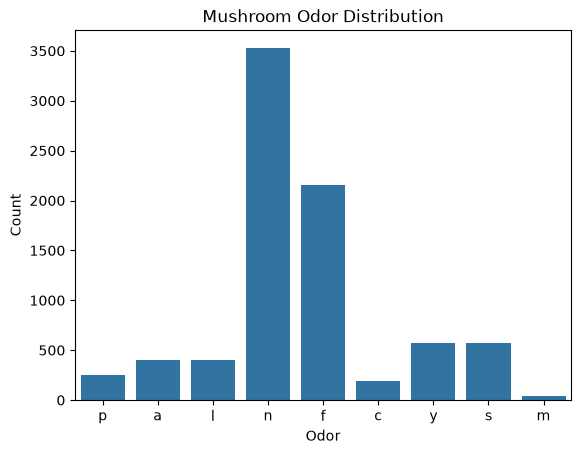

In [5]:
sns.countplot(data=df, x="odor")
plt.title("Mushroom Odor Distribution")
plt.xlabel("Odor")
plt.ylabel("Count")
plt.show()

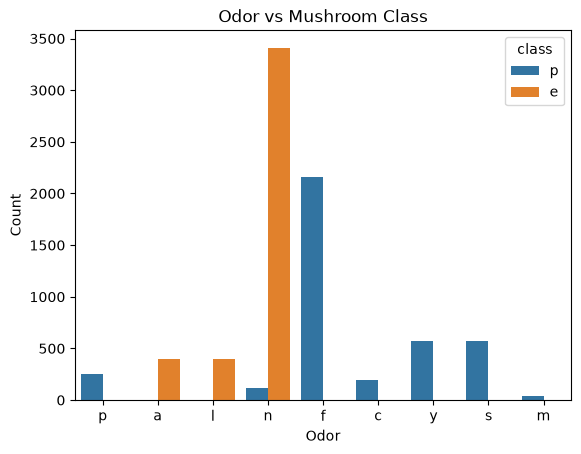

In [6]:
sns.countplot(data=df, x="odor", hue="class")
plt.title("Odor vs Mushroom Class")
plt.xlabel("Odor")
plt.ylabel("Count")
plt.show()

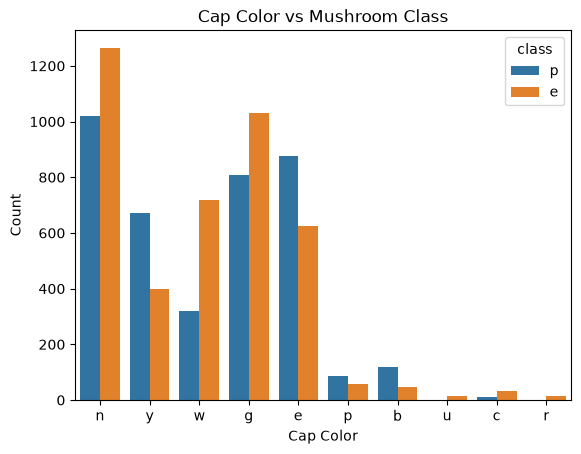

In [7]:
sns.countplot(data=df, x="cap-color", hue="class")
plt.title("Cap Color vs Mushroom Class")
plt.xlabel("Cap Color")
plt.ylabel("Count")
plt.show()

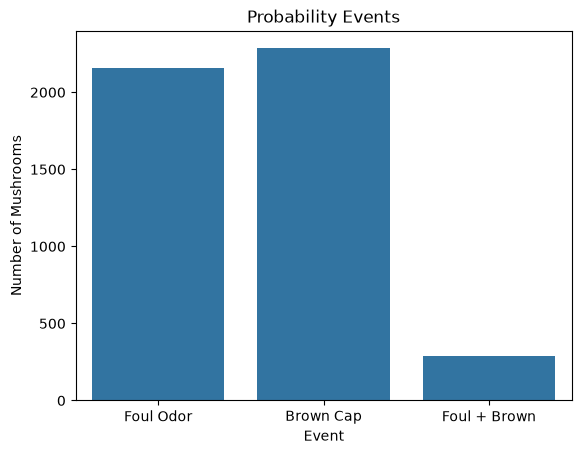

In [8]:
plot_data = pd.DataFrame({
    "Event": ["Foul Odor", "Brown Cap", "Foul + Brown"],
    "Count": [A.sum(), B.sum(), (A & B).sum()]
})

sns.barplot(data=plot_data, x="Event", y="Count")
plt.title("Probability Events")
plt.xlabel("Event")
plt.ylabel("Number of Mushrooms")
plt.show()